In [4]:
import os
import re
import math
import json
from tqdm import tqdm
import random
from dotenv import load_dotenv
from huggingface_hub import login
import numpy as np
import pickle
from openai import OpenAI
from sentence_transformers import SentenceTransformer
from items import Item
from testing import Tester
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import joblib


In [7]:
QUESTION = "How much does this cost to the nearest dollar?\n\n"
index_name = "products-vectorstore"

In [5]:
load_dotenv(override=True)
pinecone_api_key = os.getenv("PINCECONE_API_KEY")

In [4]:
from items import Item

In [5]:
with open('test.pkl', 'rb') as file:
    test = pickle.load(file)

In [8]:
from pinecone import Pinecone
pc = Pinecone(pinecone_api_key)
index = pc.Index(index_name)

In [14]:
count = 0
for i in index.list():
    print(i)
count

['doc_0', 'doc_1', 'doc_10', 'doc_100', 'doc_1000', 'doc_10000', 'doc_10001', 'doc_10002', 'doc_10003', 'doc_10004', 'doc_10005', 'doc_10006', 'doc_10007', 'doc_10008', 'doc_10009', 'doc_1001', 'doc_10010', 'doc_10011', 'doc_10012', 'doc_10013', 'doc_10014', 'doc_10015', 'doc_10016', 'doc_10017', 'doc_10018', 'doc_10019', 'doc_1002', 'doc_10020', 'doc_10021', 'doc_10022', 'doc_10023', 'doc_10024', 'doc_10025', 'doc_10026', 'doc_10027', 'doc_10028', 'doc_10029', 'doc_1003', 'doc_10030', 'doc_10031', 'doc_10032', 'doc_10033', 'doc_10034', 'doc_10035', 'doc_10036', 'doc_10037', 'doc_10038', 'doc_10039', 'doc_1004', 'doc_10040', 'doc_10041', 'doc_10042', 'doc_10043', 'doc_10044', 'doc_10045', 'doc_10046', 'doc_10047', 'doc_10048', 'doc_10049', 'doc_1005', 'doc_10050', 'doc_10051', 'doc_10052', 'doc_10053', 'doc_10054', 'doc_10055', 'doc_10056', 'doc_10057', 'doc_10058', 'doc_10059', 'doc_1006', 'doc_10060', 'doc_10061', 'doc_10062', 'doc_10063', 'doc_10064', 'doc_10065', 'doc_10066', 'doc_

KeyboardInterrupt: 

In [17]:
idx_to_fetch = [f"doc_{i}" for i in range(20000)]

vectors = []
documents = []
categories = []
prices = []
for i in tqdm(range(0, len(idx_to_fetch), 200)):
    result = index.fetch(ids=idx_to_fetch[i: i+200])
    res = result.vectors
    for j in res.values():
        vectors.append(j['values'])
        documents.append(j['metadata']['description'])
        categories.append(j['metadata']['category'])
        prices.append(j['metadata']['price'])
vectors = np.array(vectors)

  0%|          | 0/100 [00:00<?, ?it/s]

100%|██████████| 100/100 [01:15<00:00,  1.33it/s]


In [ ]:
joblib.dump(vectors, 'vectors.pkl')
joblib.dump(documents, 'documents.pkl')
joblib.dump(categories, 'categories.pkl')
joblib.dump(prices, 'prices.pkl')


In [35]:
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(vectors, prices)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [36]:
joblib.dump(rf_model, 'random_forest_model.pkl')
rf_model = joblib.load('random_forest_model.pkl')


In [30]:
from agents.openai_agent import OpenAIAgent
from agents.pricer_agent import PricerAgent
from agents.random_forest_agent import RandomForestAgent

In [31]:
openai_agent = OpenAIAgent(index)
pricer_agent = PricerAgent()
random_forest = RandomForestAgent()

In [16]:
def description(item):
    return item.prompt.split("to the nearest dollar?\n\n")[1].split("\n\nPrice is $")[0]

In [32]:
def rf(item):
    return random_forest.price(description(item))

1: Guess: $275.92 Truth: $374.41 Error: $98.49 SLE: 0.09 Item: OEM AC Compressor w/A/C Repair Kit For F...
2: Guess: $175.30 Truth: $225.11 Error: $49.81 SLE: 0.06 Item: Motorcraft YB3125 Fan Clutch
3: Guess: $253.75 Truth: $61.68 Error: $192.07 SLE: 1.97 Item: Dorman 603-159 Front Washer Fluid Reserv...
4: Guess: $326.36 Truth: $599.99 Error: $273.63 SLE: 0.37 Item: HP Premium 17.3-inch HD Plus Touchscreen...
5: Guess: $272.61 Truth: $16.99 Error: $255.62 SLE: 7.41 Item: 5-Position Super Switch Pickup Selector ...
6: Guess: $70.31 Truth: $31.99 Error: $38.32 SLE: 0.59 Item: Horror Bookmarks, Resin Horror Bookmarks...
7: Guess: $254.09 Truth: $101.79 Error: $152.30 SLE: 0.83 Item: SK6241 - Stinger 4 Gauge 6000 Series Pow...
8: Guess: $205.54 Truth: $289.00 Error: $83.46 SLE: 0.12 Item: Godox ML60Bi LED Light Kit, Handheld LED...
9: Guess: $318.51 Truth: $635.86 Error: $317.35 SLE: 0.48 Item: Randall RG75DG3PLUS G3 Plus 100-Watt Com...
10: Guess: $131.02 Truth: $65.99 Error: $65.03 SLE:

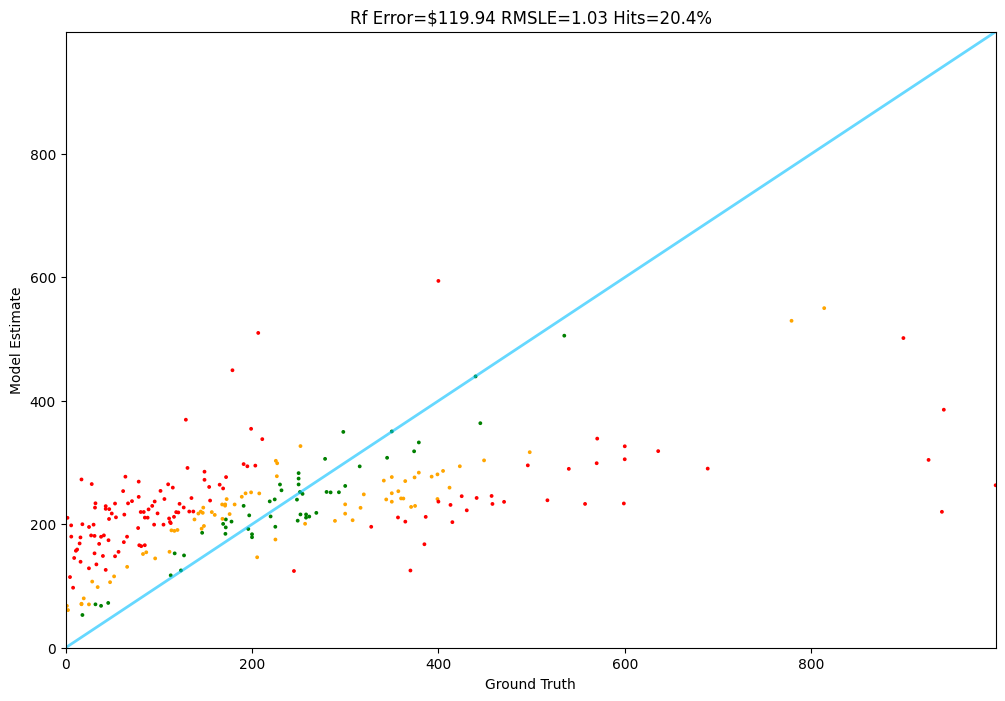

In [37]:
Tester.test(rf, test,250)

In [2]:
product = "Quadcast HyperX condenser mic for high quality audio for podcasting"

In [39]:
print(openai_agent.price(product))
print(pricer_agent.price(product))
print(random_forest.price(product))

139.99
130.0
298.04560000000004


In [40]:
pricers = []
openais = []
random_forests = []
prices = []
for item in tqdm(test[1000:1050]):
    text = description(item)
    pricers.append(pricer_agent.price(text))
    openais.append(openai_agent.price(text))
    random_forests.append(random_forest.price(text))
    prices.append(item.price)

100%|██████████| 50/50 [08:06<00:00,  9.74s/it]  


In [42]:
mins = [min(s,f,r) for s,f,r in zip(pricers, openais, random_forests)]
maxes = [max(s,f,r) for s,f,r in zip(pricers, openais, random_forests)]

X = pd.DataFrame({
    'Openai': openais,
    'Prices Fine Tuned': pricers,
    'RandomForest': random_forests,
    'Min': mins,
    'Max': maxes,
})

# Convert y to a Series
y = pd.Series(prices)

In [43]:
# Train a Linear Regression
np.random.seed(42)

lr = LinearRegression()
lr.fit(X, y)

feature_columns = X.columns.tolist()

for feature, coef in zip(feature_columns, lr.coef_):
    print(f"{feature}: {coef:.2f}")
print(f"Intercept={lr.intercept_:.2f}")

Openai: -0.22
Prices Fine Tuned: -0.06
RandomForest: -0.94
Min: 1.68
Max: 0.66
Intercept=42.38


In [44]:
joblib.dump(lr, 'ensemble_model.pkl')

['ensemble_model.pkl']

In [9]:
from agents.ensemble_agent import EnsembleAgent
ensemble = EnsembleAgent(index)

In [10]:
import logging
root = logging.getLogger()
root.setLevel(logging.INFO)

In [11]:
ensemble.price(product)

INFO:root:[Ensemble Agent] Running Ensemble Agent - collaborating with specialist, frontier and random forest agents


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:root:[Openai Agent] Openai Ai Agent is going to predict the price with context of 5 similar prodoct
INFO:httpx:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:root:[Openai Agent] Openai Agent completed - predicting $139.99
INFO:root:[Pricer Agent] Specialist Agent is calling remote fine-tuned model
INFO:root:[Pricer Agent] Received price: 130.0
INFO:root:[Random Forest Agent] Random Forest Agent is starting a prediction


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:root:[Random Forest Agent] Random Forest Agent completed - predicting $300.54
INFO:root:[Ensemble Agent] Ensemble Agent complete - returning $136.41


136.4131610275432

In [12]:
def ensemble_pricer(item):
    return max(0,ensemble.price(description(item)))

In [14]:
test = joblib.load('test.pkl')

INFO:root:[Ensemble Agent] Running Ensemble Agent - collaborating with specialist, frontier and random forest agents


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:root:[Openai Agent] Openai Ai Agent is going to predict the price with context of 5 similar prodoct
INFO:httpx:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:root:[Openai Agent] Openai Agent completed - predicting $294.41
INFO:root:[Pricer Agent] Specialist Agent is calling remote fine-tuned model
INFO:root:[Pricer Agent] Received price: 366.0
INFO:root:[Random Forest Agent] Random Forest Agent is starting a prediction


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:root:[Random Forest Agent] Random Forest Agent completed - predicting $281.79
INFO:root:[Ensemble Agent] Ensemble Agent complete - returning $403.44
INFO:root:[Ensemble Agent] Running Ensemble Agent - collaborating with specialist, frontier and random forest agents


1: Guess: $403.44 Truth: $374.41 Error: $29.03 SLE: 0.01 Item: OEM AC Compressor w/A/C Repair Kit For F...


... (241 outputs left out)

INFO:root:[Openai Agent] Openai Ai Agent is going to predict the price with context of 5 similar prodoct
INFO:httpx:HTTP Request: POST https://api.openai.com/v1/chat/completions "HTTP/1.1 200 OK"
INFO:root:[Openai Agent] Openai Agent completed - predicting $239.00
INFO:root:[Pricer Agent] Specialist Agent is calling remote fine-tuned model
INFO:root:[Pricer Agent] Received price: 399.0
INFO:root:[Random Forest Agent] Random Forest Agent is starting a prediction


Batches:   0%|          | 0/1 [00:00<?, ?it/s]

INFO:root:[Random Forest Agent] Random Forest Agent completed - predicting $427.92
INFO:root:[Ensemble Agent] Ensemble Agent complete - returning $245.11


50: Guess: $245.11 Truth: $439.88 Error: $194.77 SLE: 0.34 Item: Lenovo IdeaPad 3 14-inch Laptop, 14.0-in...


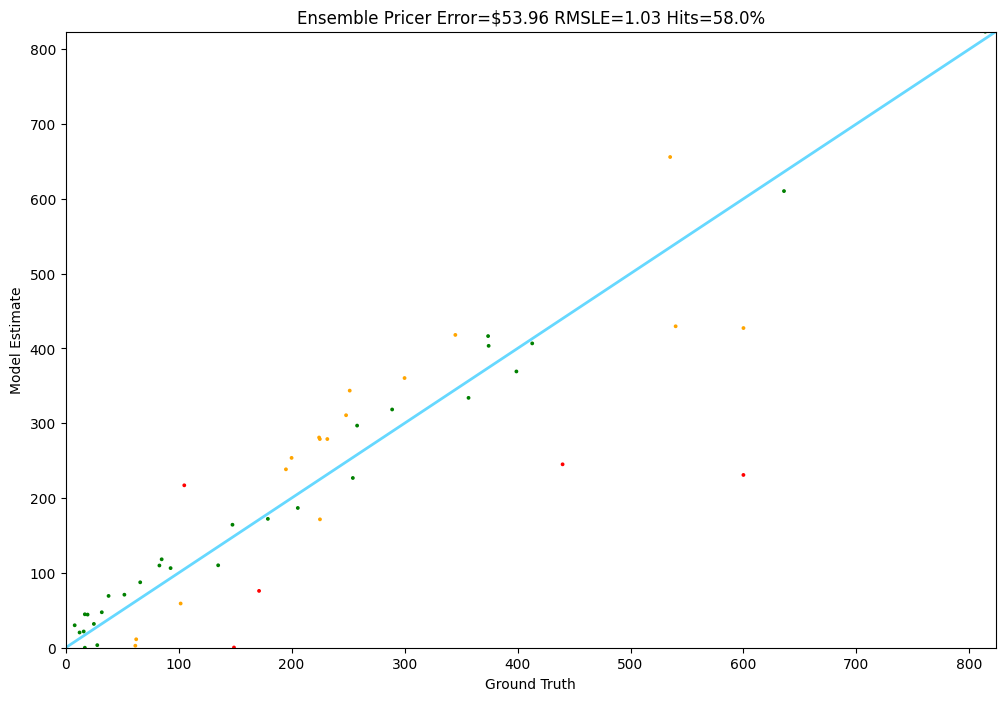

In [19]:
Tester.test(ensemble_pricer, test)